In [5]:
from rdkit import Chem
import pandas as pd

# Carga el archivo SDF usando SDMolSupplier. 
# Esto genera un iterador con los objetos moleculares.
suppl = Chem.SDMolSupplier("/home/ratam/forkC2026/Bioinf-NatProd/data/raw/torresraw/BIOFACQUIM_V2.sdf")

# Extrae las moléculas a una lista. Mantiene los objetos None (moléculas corruptas) para la estadística.
mols = [m for m in suppl]

# Imprime métricas básicas de lectura
print("Registros leídos:", len(mols))
print("No parseables:", sum(1 for m in mols if m is None))

# Extrae e imprime el nombre de los metadatos/columnas disponibles en el archivo SDF original
print("Campos disponibles:", mols[0].GetPropNames() and list(mols[0].GetPropNames()))

Registros leídos: 531
No parseables: 0
Campos disponibles: ['ID', 'Name', 'SMILES', 'Name (#1)', 'Reference', 'Year', 'Kingdom', 'Genus', 'Specie', 'DOI', 'Journal', 'Site', 'State', 'IC50_1_(M)', 'Activity_1', 'IC50_2', 'Activity_2', 'IC50_3', 'Activity_3', 'IC50_4', 'Activity_4', 'IC50_5', 'Activity_5', 'IC50_6', 'Activity_6', 'Bioactivity', 'Bioactivity(2)', 'Bioactivity(3)', 'Col27', 'Col28', 'Col29', 'Col30', 'Col31', 'Col32', 'Col33', 'Col34', 'Col35', 'Col36', 'Col37', 'Col38', 'Col39', 'Col40', 'Col41', 'Col42', 'Col43', 'Col44', 'Col45', 'Col46', 'Col47', 'Col48', 'Col49', 'Col50', 'Col51', 'Col52', 'Col53']


[08:40:16] Skipping unrecognized collection type at line 17867: MDLV30/STERAC1 BONDS=(1 13)
[08:40:16] Skipping unrecognized collection type at line 18377: MDLV30/STERAC1 BONDS=(1 13)


In [6]:
# Extraer las propiedades SDF y los objetos molécula a una lista de diccionarios
registros = []
for i, m in enumerate(mols):
    if m is not None:
        row = m.GetPropsAsDict()
        row["ID_orig"] = i
        row["ROMol"] = m  # Se guarda el objeto de RDKit para procesarlo después
        row["SMILES"] = Chem.MolToSmiles(m)
        registros.append(row)

# Crear el DataFrame principal crudo
df = pd.DataFrame(registros)

# Inicializar la bitácora en memoria para registrar el impacto de los filtros
conteos = [{"paso": "0_crudo", "entran": len(mols), "salen": len(mols), "motivo": ""}]

print(f"DataFrame creado con éxito.")
print(f"Número de filas y columnas: {df.shape}")

# Muestra la previsualización tabular en Jupyter
df.head(3)

DataFrame creado con éxito.
Número de filas y columnas: (531, 57)


,ID,Name,SMILES,Name (#1),Reference,Year,Kingdom,Genus,Specie,DOI,...,Col46,Col47,Col48,Col49,Col50,Col51,Col52,Col53,ID_orig,ROMol
0,FQNP502,Asarinin,c1cc2c(cc1C1OCC3C(c4ccc5c(c4)OCO5)OCC13)OCO2,Asarinin,Phytochemistry_2004;66_(4):487-494,2004,Plant,Stauranthus,Stauranthus_perforatus,10.1016/j.phytochem.2004.12.028,...,,,,,,,,,0,<rdkit.Chem.rdchem.Mol object at 0x746918e10d60>
1,FQNP281,Nidemin,C=C(C)C(C)(C)CC[C@@H](C)[C@H]1CC[C@@]2(C)C3CCC...,Nidemin,Nat_Prod_Lett_2002;16(2):81-6,2002,Plant,Scaphyglottis,Scaphyglottis_livida,10.1080/10575630290019967,...,,,,,,,,,1,<rdkit.Chem.rdchem.Mol object at 0x746918e112a0>
2,FQNP553,Axinisothiocyanate_N,C=C(C)[C@]1(OO)CC[C@@]2(C)CCC[C@@](C)(N=C=S)[C...,Axinisothiocyanate_N,J_Nat_Prod_2008;71_(12):2004-2010,2008,Animal,Axinyssa,Axinyssa_isabela,10.1021/np800465n,...,,,,,,,,,2,<rdkit.Chem.rdchem.Mol object at 0x746918e11310>


In [7]:
from rdkit import Chem, RDLogger
from rdkit.Chem.MolStandardize import rdMolStandardize

# Silencia advertencias ruidosas de RDKit en la salida de la celda
RDLogger.DisableLog("rdApp.*")   

# Inicialización de las reglas de limpieza estructural
normalizador = rdMolStandardize.Normalizer()              # Arregla grupos funcionales anómalos
fragmento    = rdMolStandardize.LargestFragmentChooser()  # Elimina contraiones y disolventes
descargador  = rdMolStandardize.Uncharger()               # Neutraliza cargas
reionizador  = rdMolStandardize.Reionizer()               # Ajusta protones al sitio fisiológicamente correcto
tautomeros   = rdMolStandardize.TautomerEnumerator()      # Enumera tautómeros canónicos

def estandarizar(mol):
    """Aplica la secuencia de limpieza y devuelve la molécula estandarizada, o None en caso de error."""
    try:
        mol = normalizador.normalize(mol)
        mol = fragmento.choose(mol)
        mol = descargador.uncharge(mol)
        mol = reionizador.reionize(mol)
        mol = tautomeros.Canonicalize(mol)
        Chem.SanitizeMol(mol)
        return mol
    except Exception:
        return None

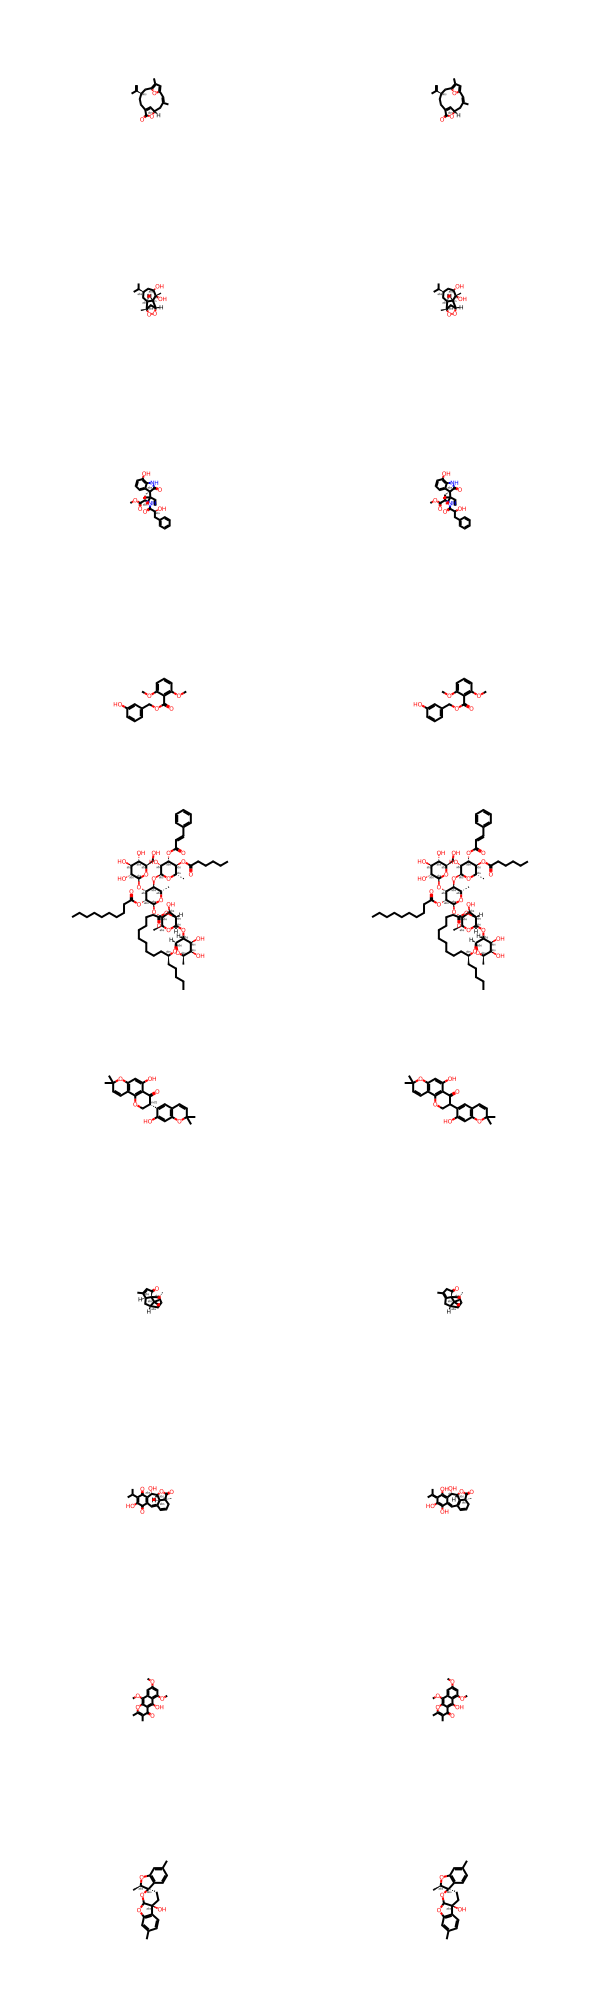

In [8]:
import random
from rdkit.Chem import Draw

random.seed(42) # Fija una semilla para que siempre salga la misma muestra aleatoria

# Toma 10 moléculas al azar
muestra = random.sample([m for m in mols if m is not None], 10)
# Crea una lista plana alternando: molécula cruda, molécula estandarizada
pares = [m for orig in muestra for m in (orig, estandarizar(orig))]

# Genera una cuadrícula de imágenes comparativas
img = Draw.MolsToGridImage(pares, molsPerRow=2, subImgSize=(300, 200))

# Guarda la imagen en formato binario en la ruta del repositorio
with open("/home/ratam/forkC2026/Bioinf-NatProd/figures/torresfig/figC1/torrescontrolstnd.png", "wb") as f:
    f.write(img.data)

# CORRECCIÓN: Llamamos a 'img' para que el Notebook imprima la imagen visualmente.
img

In [9]:
from rdkit.Chem import Descriptors
from rdkit import Chem

# Define un set de elementos orgánicos y halógenos. Cualquier metal pesado o elemento raro será filtrado.
ELEMENTOS = {"H", "B", "C", "N", "O", "F", "Si", "P", "S", "Cl", "Se", "Br", "I"}

def elementos_ok(mol):
    """Devuelve True si TODOS los átomos de la molécula están en la lista ELEMENTOS."""
    return all(a.GetSymbol() in ELEMENTOS for a in mol.GetAtoms())

# Ventana de peso molecular
MW_MIN, MW_MAX = 50, 5000

def masa_ok(mol):
    """Devuelve True si la masa de la molécula está dentro de los límites establecidos."""
    return MW_MIN <= Descriptors.MolWt(mol) <= MW_MAX

def obtener_esqueleto(mol):
    """Genera el InChIKey y devuelve el primer bloque (conectividad atómica en 2D), ignorando la estereoquímica para buscar duplicados."""
    inchikey = Chem.MolToInchiKey(mol)
    return inchikey.split("-")[0]

print("Funciones cargadas exitosamente sin errores.")

Funciones cargadas exitosamente sin errores.


In [10]:
# 1. Aplicar estandarización
df['ROMol_std'] = df['ROMol'].apply(estandarizar)
df_std = df.dropna(subset=['ROMol_std']).copy()
conteos.append({"paso": "1_estandarizacion", "entran": len(df), "salen": len(df_std), "motivo": "Fallo al estandarizar o limpiar sales"})

# 2. Aplicar filtro de elementos permitidos
mask_elementos = df_std['ROMol_std'].apply(elementos_ok)
df_elem = df_std[mask_elementos].copy()
conteos.append({"paso": "2_elementos", "entran": len(df_std), "salen": len(df_elem), "motivo": "Contiene metales o inorgánicos"})

# 3. Aplicar filtro de masa
mask_masa = df_elem['ROMol_std'].apply(masa_ok)
df_masa = df_elem[mask_masa].copy()
conteos.append({"paso": "3_masa", "entran": len(df_elem), "salen": len(df_masa), "motivo": "Masa < 50 o > 5000"})

# 4. Eliminar duplicados mediante el esqueleto InChIKey
df_masa['Esqueleto_InChIKey'] = df_masa['ROMol_std'].apply(obtener_esqueleto)
df_curado = df_masa.drop_duplicates(subset=['Esqueleto_InChIKey'], keep='first').copy()
conteos.append({"paso": "4_duplicados", "entran": len(df_masa), "salen": len(df_curado), "motivo": "Estructuras base duplicadas (estereoisómeros ignorados)"})

# 5. Generar SMILES final y limpiar columnas no serializables (los objetos Mol rompen la exportación a CSV)
df_curado['SMILES_curado'] = df_curado['ROMol_std'].apply(Chem.MolToSmiles)
df_curado = df_curado.drop(columns=['ROMol', 'ROMol_std'])

print(f"Curación finalizada. Sobrevivieron {len(df_curado)} moléculas únicas.")

Curación finalizada. Sobrevivieron 503 moléculas únicas.


In [11]:
import os
import pandas as pd
from rdkit import Chem

# Definición de rutas específicas de resultados y procesamiento
ruta_results_dir = "/home/ratam/forkC2026/Bioinf-NatProd/results/torresresults/torresC1"
ruta_processed_dir = "/home/ratam/forkC2026/Bioinf-NatProd/data/processed/torresprocessed/torresC1"

ruta_conteos = f"{ruta_results_dir}/torres_conteos_BIOFACQUIM_V2.csv"
ruta_csv = f"{ruta_processed_dir}/torresBIOFACQUIM_V2curado.csv"
ruta_sdf = f"{ruta_processed_dir}/torresBIOFACQUIM_V2curado.sdf"

os.makedirs(ruta_results_dir, exist_ok=True)
os.makedirs(ruta_processed_dir, exist_ok=True)

# --- Construcción del DataFrame estadístico de conteos ---
df_conteos = pd.DataFrame(conteos)
total_inicial = df_conteos.loc[0, "entran"]
df_conteos["descartados"] = df_conteos["entran"] - df_conteos["salen"]
df_conteos["pct_retencion_paso"] = (df_conteos["salen"] / df_conteos["entran"] * 100).round(2)
df_conteos["pct_retencion_total"] = (df_conteos["salen"] / total_inicial * 100).round(2)

df_conteos = df_conteos[["paso", "entran", "salen", "descartados", "pct_retencion_paso", "pct_retencion_total", "motivo"]]

# --- Exportación de archivos ---
df_conteos.to_csv(ruta_conteos, index=False)
df_curado.to_csv(ruta_csv, index=False)

# Reconstruir las moléculas desde el SMILES curado para guardar el archivo SDF junto con su metadata tabular
writer = Chem.SDWriter(ruta_sdf)
for index, row in df_curado.iterrows():
    mol = Chem.MolFromSmiles(row['SMILES_curado'])
    if mol is not None:
        for col_name in df_curado.columns:
            mol.SetProp(str(col_name), str(row[col_name]))
        writer.write(mol)
writer.close()

print(f"¡Archivos exportados exitosamente en:\n - {ruta_conteos}\n - {ruta_csv}\n - {ruta_sdf}")

# Muestra el reporte final de retención en Jupyter
df_conteos

¡Archivos exportados exitosamente en:
 - /home/ratam/forkC2026/Bioinf-NatProd/results/torresresults/torresC1/torres_conteos_BIOFACQUIM_V2.csv
 - /home/ratam/forkC2026/Bioinf-NatProd/data/processed/torresprocessed/torresC1/torresBIOFACQUIM_V2curado.csv
 - /home/ratam/forkC2026/Bioinf-NatProd/data/processed/torresprocessed/torresC1/torresBIOFACQUIM_V2curado.sdf


,paso,entran,salen,descartados,pct_retencion_paso,pct_retencion_total,motivo
0,0_crudo,531,531,0,100.00,100.00,
1,1_estandarizacion,531,531,0,100.00,100.00,Fallo al estandarizar o limpiar sales
2,2_elementos,531,531,0,100.00,100.00,Contiene metales o inorgánicos
3,3_masa,531,531,0,100.00,100.00,Masa < 50 o > 5000
4,4_duplicados,531,503,28,94.73,94.73,Estructuras base duplicadas (estereoisómeros i...
